# Bộ lọc Kalman rời rạc cho vật rơi

## A. Thiết lập bài toán

Vật rơi trong trường gia tốc không đổi $\ddot z=-g$ với $g=1$ theo sách.
Với $x_k=[z_k,\dot z_k]^\top$ và $\Delta t=1$, mô hình là

$$
x_{k+1}=\Phi x_k+b,\qquad
\Phi=\begin{bmatrix}1&1\\0&1\end{bmatrix},\qquad
b=-g\begin{bmatrix}1/2\\1\end{bmatrix}.
$$

Hệ có $Q=0$. Phép đo $y_k=Mx_k+v_k$ có $M=[1\;\;0]$, với nhiễu
trung bình bằng 0 và phương sai $R=1$. Cảm biến chỉ đo vị trí.
Vận tốc được suy ra từ sự thay đổi vị trí qua các lần đo. Tại $k=0$
chỉ có ước lượng tiên nghiệm. Phép đo đầu tiên là $y_1$.

Dữ liệu và số đối chiếu lấy từ A. H. Jazwinski, *Stochastic Processes and
Filtering Theory*, Chương 8 §5, tr. 287–292.
[PDF trong repo](../../../docs/Stochastic%20Process%20and%20Filter%20Theory/Stochastic%20Processes%20and%20Filtering%20Theory-277-344.pdf#page=22)

In [1]:
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

gravity = 1.0
phi = np.array([[1.0, 1.0], [0.0, 1.0]])
gravity_step = -gravity * np.array([0.5, 1.0])
measurement_matrix = np.array([[1.0, 0.0]])
measurement_variance = 1.0

initial_estimate = np.array([95.0, 1.0])
initial_covariance = np.diag([10.0, 1.0])
true_initial_state = np.array([100.0, 0.0])

# Bảng 8.2, theo thứ tự từ y_1 đến y_6.
observations = np.array([100.0, 97.9, 94.4, 92.7, 87.3, 82.1])
time_steps = np.arange(observations.size + 1)

## B. Truy hồi Kalman

**Dự báo.** Truyền trạng thái và hiệp phương sai từ $k$ sang $k+1$.

$$
\hat x_{k+1|k}=\Phi\hat x_{k|k}+b,\qquad
P_{k+1|k}=\Phi P_{k|k}\Phi^\top.
$$

**Cập nhật.** Đặt $P^-=P_{k+1|k}$ và $\hat x^-=\hat x_{k+1|k}$.
Phương sai $S$ gồm bất định của vị trí dự báo và nhiễu phép đo.
Vì $S$ là vô hướng, nhân với $S^{-1}$ tương đương chia cho $S$.

$$
\begin{aligned}
S&=MP^-M^\top+R,& K&=P^-M^\top S^{-1},\\
\hat x_{k+1|k+1}&=\hat x^-+K(y_{k+1}-M\hat x^-),&
P_{k+1|k+1}&=(I-KM)P^-.
\end{aligned}
$$

Phần tử $P^-_{21}$ cho phép sai lệch của phép đo vị trí hiệu chỉnh
cả vận tốc.

In [2]:
def run_filter(initial_covariance):
    """Tính ước lượng và hiệp phương sai tại k = 0, ..., 6."""
    state_estimates = np.empty((time_steps.size, 2))
    covariances = np.empty((time_steps.size, 2, 2))
    state_estimates[0] = initial_estimate
    covariances[0] = initial_covariance
    identity = np.eye(2)

    for k, observation in enumerate(observations, start=1):
        # Dự báo trạng thái và bất định theo mô hình vật rơi.
        predicted_state = phi @ state_estimates[k - 1] + gravity_step
        predicted_covariance = phi @ covariances[k - 1] @ phi.T

        # Cập nhật theo sai lệch giữa phép đo và vị trí dự báo.
        cross_covariance = predicted_covariance @ measurement_matrix.T
        innovation_variance = (
            (measurement_matrix @ cross_covariance).item()
            + measurement_variance
        )
        kalman_gain = cross_covariance / innovation_variance
        innovation = observation - measurement_matrix @ predicted_state
        state_estimate = predicted_state + kalman_gain @ innovation
        covariance = (
            (identity - kalman_gain @ measurement_matrix)
            @ predicted_covariance
        )

        state_estimates[k] = state_estimate
        covariances[k] = covariance

    return state_estimates, covariances


state_estimates, covariances = run_filter(initial_covariance)

## C. Đối chiếu với Bảng 8.2

Tính quỹ đạo thật từ $x_0=[100,0]^\top$ và gia tốc $-1$. Trong bốn
cột cuối, mỗi ô có dạng **tính được / sách**. Bảng 8.2 in phương sai
$P_{11}$, $P_{22}$ nên lấy căn bậc hai để đối chiếu độ lệch chuẩn.

In [3]:
true_position = (
    true_initial_state[0]
    + true_initial_state[1] * time_steps
    - 0.5 * gravity * time_steps**2
)
true_velocity = true_initial_state[1] - gravity * time_steps
true_states = np.column_stack((true_position, true_velocity))
standard_deviations = np.sqrt(covariances.diagonal(axis1=1, axis2=2))

textbook_states = np.array([
    [95.0, 1.0],
    [99.6, 0.36],
    [98.4, -1.2],
    [95.3, -2.3],
    [92.6, -3.25],
    [87.9, -4.6],
    [82.4, -5.7],
])
textbook_variances = np.array([
    [10.0, 1.0],
    [0.88, 0.92],
    [0.66, 0.57],
    [0.66, 0.30],
    [0.62, 0.16],
    [0.56, 0.10],
    [0.50, 0.06],
])
textbook_standard_deviations = np.sqrt(textbook_variances)

rows = [
    "| $k$ | Vị trí thật | Vận tốc thật | Phép đo | "
    "Vị trí ước lượng | Vận tốc ước lượng | "
    r"$\sigma_z$ | $\sigma_{\dot z}$ |",
    "|---:|---:|---:|---:|---:|---:|---:|---:|",
]
for k in time_steps:
    measurement = "—" if k == 0 else f"{observations[k - 1]:.1f}"
    values = np.r_[state_estimates[k], standard_deviations[k]]
    reference = np.r_[
        textbook_states[k], textbook_standard_deviations[k]
    ]
    comparison = [
        f"{value:.3f} / {book:.3f}"
        for value, book in zip(values, reference)
    ]
    row = [
        str(k), f"{true_position[k]:.1f}", f"{true_velocity[k]:.1f}",
        measurement, *comparison,
    ]
    rows.append("| " + " | ".join(row) + " |")

display(Markdown("\n".join(rows)))

| $k$ | Vị trí thật | Vận tốc thật | Phép đo | Vị trí ước lượng | Vận tốc ước lượng | $\sigma_z$ | $\sigma_{\dot z}$ |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 0 | 100.0 | 0.0 | — | 95.000 / 95.000 | 1.000 / 1.000 | 3.162 / 3.162 | 1.000 / 1.000 |
| 1 | 99.5 | -1.0 | 100.0 | 99.625 / 99.600 | 0.375 / 0.360 | 0.957 / 0.938 | 0.957 / 0.959 |
| 2 | 98.0 | -2.0 | 97.9 | 98.433 / 98.400 | -1.158 / -1.200 | 0.816 / 0.812 | 0.764 / 0.755 |
| 3 | 95.5 | -3.0 | 94.4 | 95.214 / 95.300 | -2.905 / -2.300 | 0.811 / 0.812 | 0.543 / 0.548 |
| 4 | 92.0 | -4.0 | 92.7 | 92.355 / 92.600 | -3.694 / -3.250 | 0.783 / 0.787 | 0.389 / 0.400 |
| 5 | 87.5 | -5.0 | 87.3 | 87.685 / 87.900 | -4.844 / -4.600 | 0.744 / 0.748 | 0.290 / 0.316 |
| 6 | 82.0 | -6.0 | 82.1 | 82.222 / 82.400 | -5.875 / -5.700 | 0.704 / 0.707 | 0.225 / 0.245 |

In [4]:
final_state = state_estimates[-1]
final_covariance = covariances[-1]
textbook_final_state = textbook_states[-1]
textbook_final_covariance = np.array([[0.50, 0.14], [0.14, 0.06]])

# Nửa đơn vị ở chữ số cuối sách in.
state_matches = np.allclose(
    final_state, textbook_final_state, rtol=0, atol=0.05
)
covariance_matches = np.allclose(
    final_covariance, textbook_final_covariance, rtol=0, atol=0.005
)

print("Trạng thái tại k = 6, tính được và sách")
print(np.round(final_state, 6), textbook_final_state)
print("Khớp trong dung sai 0.05:", "Có" if state_matches else "Không")

print("\nHiệp phương sai tại k = 6, tính được và sách")
print(np.round(final_covariance, 6))
print(textbook_final_covariance)
print(
    "Khớp trong dung sai 0.005:",
    "Có" if covariance_matches else "Không",
)

Trạng thái tại k = 6, tính được và sách
[82.221631 -5.874875] [82.4 -5.7]
Khớp trong dung sai 0.05: Không

Hiệp phương sai tại k = 6, tính được và sách
[[0.49584  0.129784]
 [0.129784 0.050749]]
[[0.5  0.14]
 [0.14 0.06]]
Khớp trong dung sai 0.005: Không


Hai phép kiểm tra cuối cho thấy độ lệch vượt quá dung sai làm tròn
theo số chữ số in. Ở bước đầu, sách dùng gain đã làm tròn
$[0.92,\,0.08]^\top$ và thu được $\hat x_{1|1}=[99.64,\,0.36]^\top$
(tr. 289). Dùng gain chính xác $[11/12,\,1/12]^\top$ cho
$[99.625,\,0.375]^\top$ và $P_{11}(1|1)=11/12\approx0.917$,
trong khi bảng in $0.88$.

## D. Sai số ước lượng và biên $\pm 1\sigma$

Theo quy ước của Hình 8.1–8.2, sai số là $x_k-\hat x_{k|k}$.
Hai đường nét đứt biểu diễn $\pm\sqrt{P_{ii}(k|k)}$ tại từng bước.

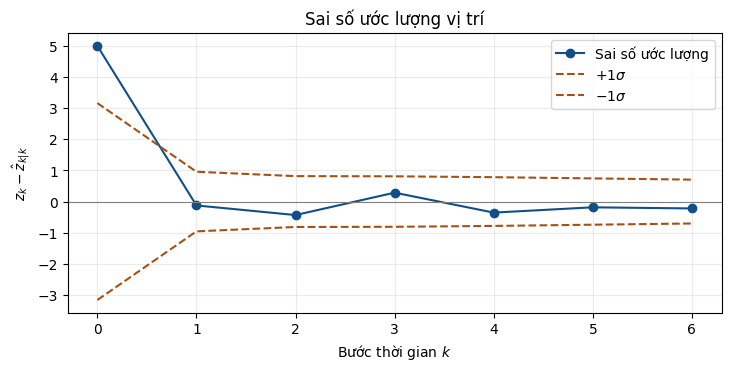

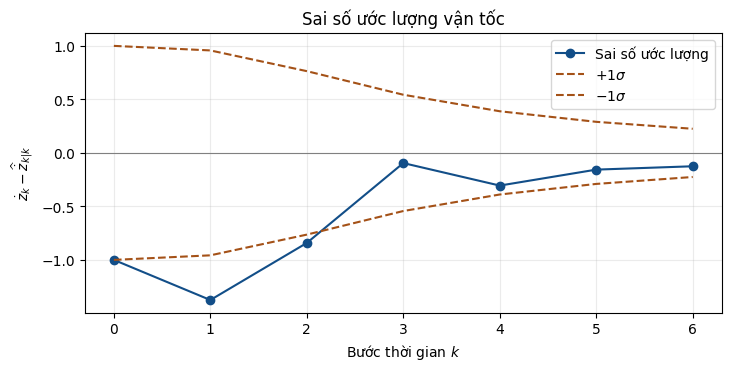

In [5]:
estimation_errors = true_states - state_estimates
components = [
    ("vị trí", r"$z_k-\hat z_{k|k}$"),
    ("vận tốc", r"$\dot z_k-\widehat{\dot z}_{k|k}$"),
]

for component, (label, error_label) in enumerate(components):
    _, ax = plt.subplots(figsize=(7.2, 3.6), layout="constrained")
    sigma = standard_deviations[:, component]

    ax.plot(
        time_steps, estimation_errors[:, component],
        "o-", color="#124E88", label="Sai số ước lượng",
    )
    ax.plot(
        time_steps, sigma, "--", color="#A45117", label=r"$+1\sigma$"
    )
    ax.plot(
        time_steps, -sigma, "--", color="#A45117", label=r"$-1\sigma$"
    )
    ax.axhline(0, color="0.5", linewidth=0.8)
    ax.set(
        title=f"Sai số ước lượng {label}",
        xlabel="Bước thời gian $k$",
        ylabel=error_label,
        xticks=time_steps,
    )
    ax.grid(alpha=0.25)
    ax.legend()
    plt.show()

Phép đo đầu làm $\sigma_z$ giảm từ $3.162$ xuống $0.957$, còn
$\sigma_{\dot z}$ chỉ giảm từ $1.000$ xuống $0.957$. Từ lần đo thứ hai,
chênh lệch giữa các vị trí cung cấp thêm thông tin về vận tốc, nên
$\sigma_{\dot z}$ giảm rõ hơn. Biên $1\sigma$ diễn tả độ bất định của
bộ lọc, vì vậy sai số của một lần chạy có thể vượt biên.

## E. Độ nhạy với hiệp phương sai ban đầu

Chạy lại cùng truy hồi với $P'_{0|0}=\operatorname{diag}(5,2)$ và
tính $\Delta P_6=P_{6|6}-P'_{6|6}$ theo quy ước của sách.

In [6]:
alternative_initial_covariance = np.diag([5.0, 2.0])
_, alternative_covariances = run_filter(alternative_initial_covariance)
alternative_final_covariance = alternative_covariances[-1]

initial_difference = initial_covariance - alternative_initial_covariance
final_difference = final_covariance - alternative_final_covariance
textbook_alternative_covariance = np.array([
    [0.48, 0.13],
    [0.13, 0.055],
])
alternative_matches = np.allclose(
    alternative_final_covariance,
    textbook_alternative_covariance,
    rtol=0,
    atol=np.array([[0.005, 0.005], [0.005, 0.0005]]),
)

print("P(6|6)   với P₀ = diag(10, 1)")
print(np.round(final_covariance, 6))
print("\nP′(6|6)  với P′₀ = diag(5, 2)")
print(np.round(alternative_final_covariance, 6))
print("\nΔP₆ = P(6|6) − P′(6|6)")
print(np.round(final_difference, 6))
print("\nP′(6|6) in trong sách")
print(textbook_alternative_covariance)
print(
    "Khớp trong dung sai theo từng phần tử:",
    "Có" if alternative_matches else "Không",
)

print(f"\n‖ΔP₀‖²_F = {np.sum(initial_difference**2):.6g}")
print(f"‖ΔP₆‖²_F = {np.sum(final_difference**2):.6g}")

P(6|6)   với P₀ = diag(10, 1)
[[0.49584  0.129784]
 [0.129784 0.050749]]

P′(6|6)  với P′₀ = diag(5, 2)
[[0.496437 0.128266]
 [0.128266 0.049089]]

ΔP₆ = P(6|6) − P′(6|6)
[[-0.000597  0.001518]
 [ 0.001518  0.001659]]

P′(6|6) in trong sách
[[0.48  0.13 ]
 [0.13  0.055]]
Khớp trong dung sai theo từng phần tử: Không

‖ΔP₀‖²_F = 26
‖ΔP₆‖²_F = 7.71596e-06


Các phép đo vị trí tích lũy thông tin về cả vị trí lẫn vận tốc.
Sau sáu lần cập nhật, tổng bình phương các phần tử của $\Delta P$
giảm từ $26$ xuống cỡ $10^{-5}$. Đây là hiện tượng **quên hiệp phương
sai ban đầu** trong ví dụ này. Giá trị $P'_{6|6}$ trên tr. 291 được
tính từ các ma trận thông tin đã làm tròn. Phép truy hồi ở đây giữ
đầy đủ độ chính xác số.